In [102]:
from pandas_datareader import data
import matplotlib.pyplot as plt
import pandas as pd
import datetime as dt
import urllib.request, json
import os
import numpy as np
import tensorflow as tf # This code has been tested with TensorFlow 1.6
from sklearn.preprocessing import MinMaxScaler

In [103]:
import pandas as pd
import os
import urllib.request
import json
import datetime as dt
import zipfile

data_source = 'kaggle' # alphavantage or kaggle

if data_source == 'alphavantage':
  # ====================== Loading Data from Alpha Vantage ==================================

  api_key = '<your API key>'

  #American Airlines stock market prices
  ticker = "AAL"

  # JSON file with all the stock market data from AAL from the last 20 years
  url_string = "https://www.alphavantage.co/query?function=TIME_SERIES_DAILY&symbol=%s&outputsize=full&apikey=%s"%(ticker,api_key)

  # Save data to this file
  file_to_save = 'stock_market_data-%s.csv'%ticker

  # If you haven't already saved data,
  # Go ahead and grab the data from the url
  # And store date, low, high, volume, close, open values to a Pandas DataFrame
  if not os.path.exists(file_to_save):
    with urllib.request.urlopen(url_string) as url:
      data = json.loads(url.read().decode())
      # extract stock market data
      data = data['Time Series (Daily)']
      df = pd.DataFrame(columns=['Date','Low','High','Close','Open'])
      for k,v in data.items():
        date = dt.datetime.strptime(k, '%Y-%m-%d')
        data_row = [date.date(),float(v['3. low']),float(v['2. high']),
                    float(v['4. close']), float(v['1. open'])]
        df.loc[-1,:] = data_row
        df.index = df.index + 1
    print('Data saved to : %s'%file_to_save)
    df.to_csv(file_to_save)

  #If the data is already there, just load it from the CSV
  else:
    print('File already exists. Loading data from CSV')
    df = pd.read_csv(file_to_save)

else:
   # ====================== Loading Data from Kaggle ==================================
    # If the Stocks folder doesn't exist but we have the zip file, try to extract it
    if not os.path.exists('Stocks') and os.path.exists('archive (3).zip'):
        print('Extracting dataset archive...')
        try:
            with zipfile.ZipFile('archive (3).zip', 'r') as zip_ref:
                zip_ref.extractall('.')
        except Exception as e:
            print('Warning: Failed to extract archive (3).zip due to corruption or OS error. Skipping extraction.')

    # Fallback to local files if the path is still not found
    target_file = os.path.join('Stocks','hpq.us.txt')
    if not os.path.exists(target_file) and os.path.exists('aal.us.txt'):
        target_file = 'aal.us.txt'
        print('hpq.us.txt not found. Using local aal.us.txt instead.')

    df = pd.read_csv(target_file,delimiter=',',usecols=['Date','Open','High','Low','Close'])
    print('Loaded data successfully')

Extracting dataset archive...
hpq.us.txt not found. Using local aal.us.txt instead.
Loaded data successfully


In [104]:
# Data saved to : stock_market_data-AAL.csv

### **Data Exploration**

In [105]:
# Sort DataFrame by date
df = df.sort_values('Date')

# Double check the result
df.head()

,Date,Open,High,Low,Close
0,2013-12-10,23.698,24.345,23.610,24.064
1,2013-12-11,24.607,26.288,24.539,25.139
2,2013-12-12,25.342,25.832,24.616,24.616
3,2013-12-13,24.771,25.437,24.684,25.369
4,2013-12-16,25.749,25.888,25.485,25.739


### **Data visualisation**

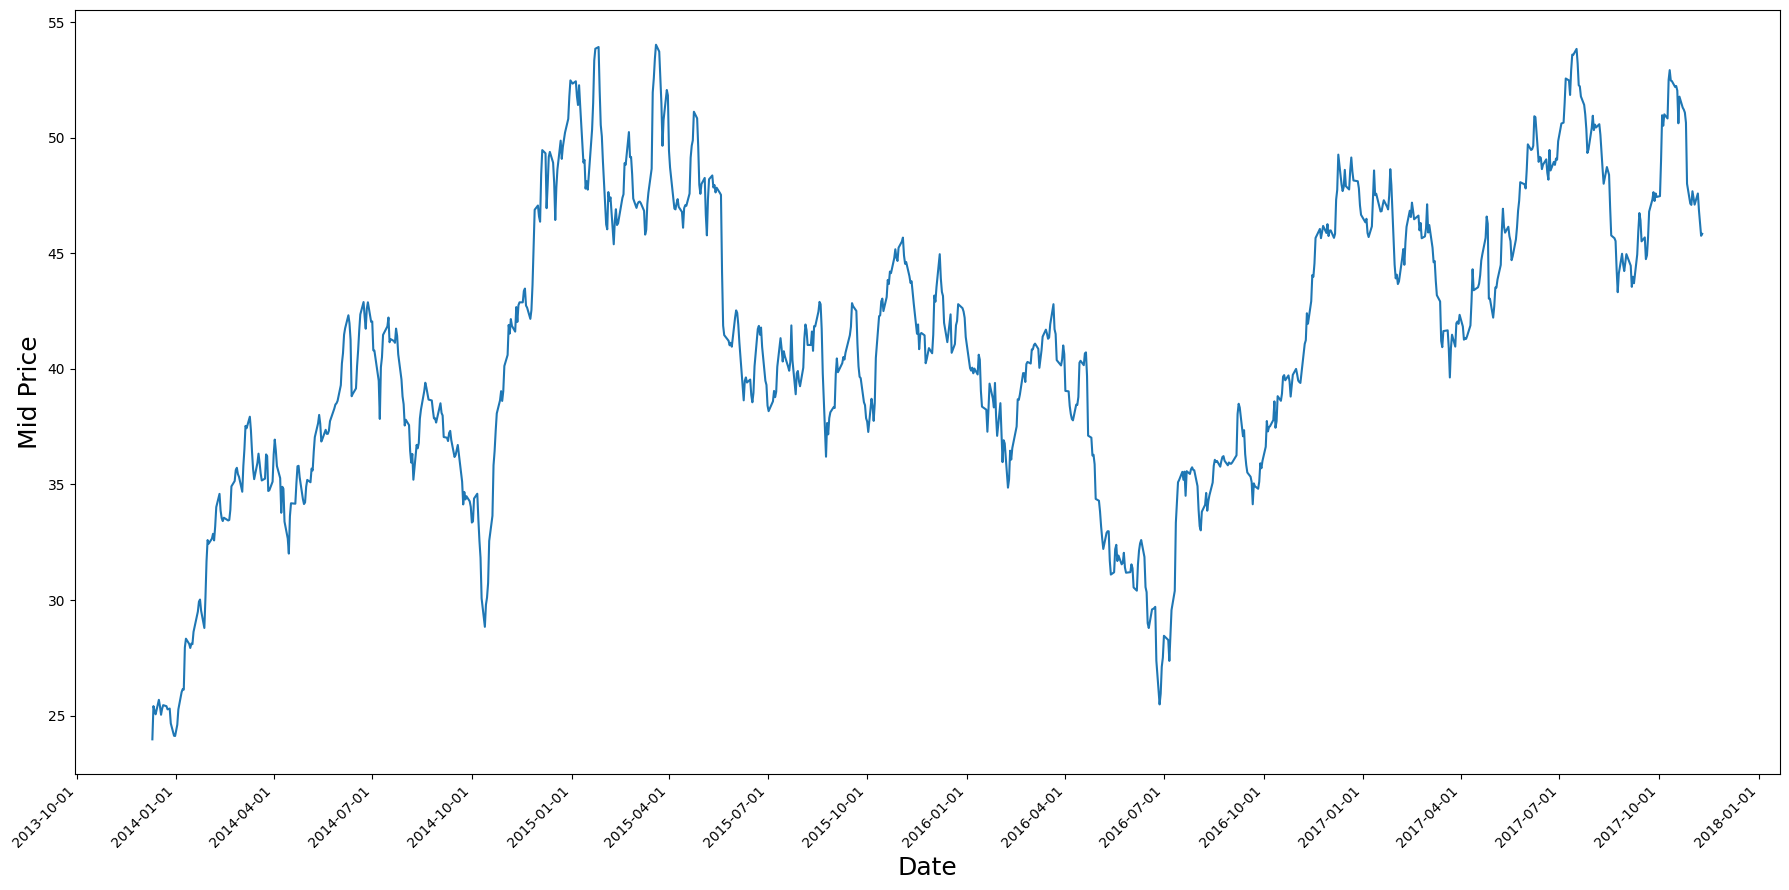

In [106]:
import matplotlib.dates as mdates

df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

plt.figure(figsize=(18,9))
plt.plot(df['Date'], (df['Low'] + df['High']) / 2.0)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10], bymonthday=1))  # quarter starts
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))                         # 2014-01-01 format

plt.xticks(rotation=45, ha='right')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Mid Price', fontsize=18)
plt.tight_layout()
plt.show()

### **Splitting Data into a Training Set and a Test Set**

In [107]:
# First calculate the mid prices from the highest and lowest
high_prices = df.loc[:,'High'].values
low_prices = df.loc[:,'Low'].values
mid_prices = (high_prices+low_prices) / 2.0

In [108]:
# Split the data 80/20
split = int(len(mid_prices) * 0.8)
train_data = mid_prices[:split]
test_data = mid_prices[split:]

### **Normalising Data**

In [109]:
scaler = MinMaxScaler()
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)

In [110]:
# Train the scaler on each window of training data
smoothing_window_size = 200
for di in range(0, len(train_data), smoothing_window_size):
    scaler.fit(train_data[di:di+smoothing_window_size, :])
    train_data[di:di+smoothing_window_size, :] = scaler.transform(train_data[di:di+smoothing_window_size, :])

# you normalise the last bit of remaining data (only if there is any left)
if di + smoothing_window_size < len(train_data):
    scaler.fit(train_data[di+smoothing_window_size:, :])
    train_data[di+smoothing_window_size:, :] = scaler.transform(train_data[di+smoothing_window_size:, :])

In [111]:
# Reshape both train and test data
train_data = train_data.reshape(-1)

# Normalise test data
test_data = scaler.transform(test_data).reshape(-1)

In [112]:
# Now perform exponential moving average smoothing
# So the data will have a smoother curve than the original ragged data
EMA = 0.0
gamma = 0.1
for ti in range(len(train_data)):
  EMA = gamma*train_data[ti] + (1-gamma)*EMA
  train_data[ti] = EMA

# Used for visualisation and test purposes
all_mid_data = np.concatenate([train_data, test_data],axis=0)

### **Standard Average**

In [113]:
window_size = 100
N = train_data.size
std_avg_predictions = []
std_avg_x = []
mse_errors = []

for pred_idx in range(window_size,N):

  if pred_idx>=N:
    date = dt.datetime.strptime(k, '%Y-%m-%d').date() + dt.timedelta(days=1)
  else:
    date = df.loc[pred_idx,'Date']

  std_avg_predictions.append(np.mean(train_data[pred_idx-window_size:pred_idx]))
  mse_errors.append((std_avg_predictions[-1]-train_data[pred_idx])**2)
  std_avg_x.append(date)

print('MSE error for standard averaging: %.5f' % (0.5*np.mean(mse_errors)))

MSE error for standard averaging: 0.01975


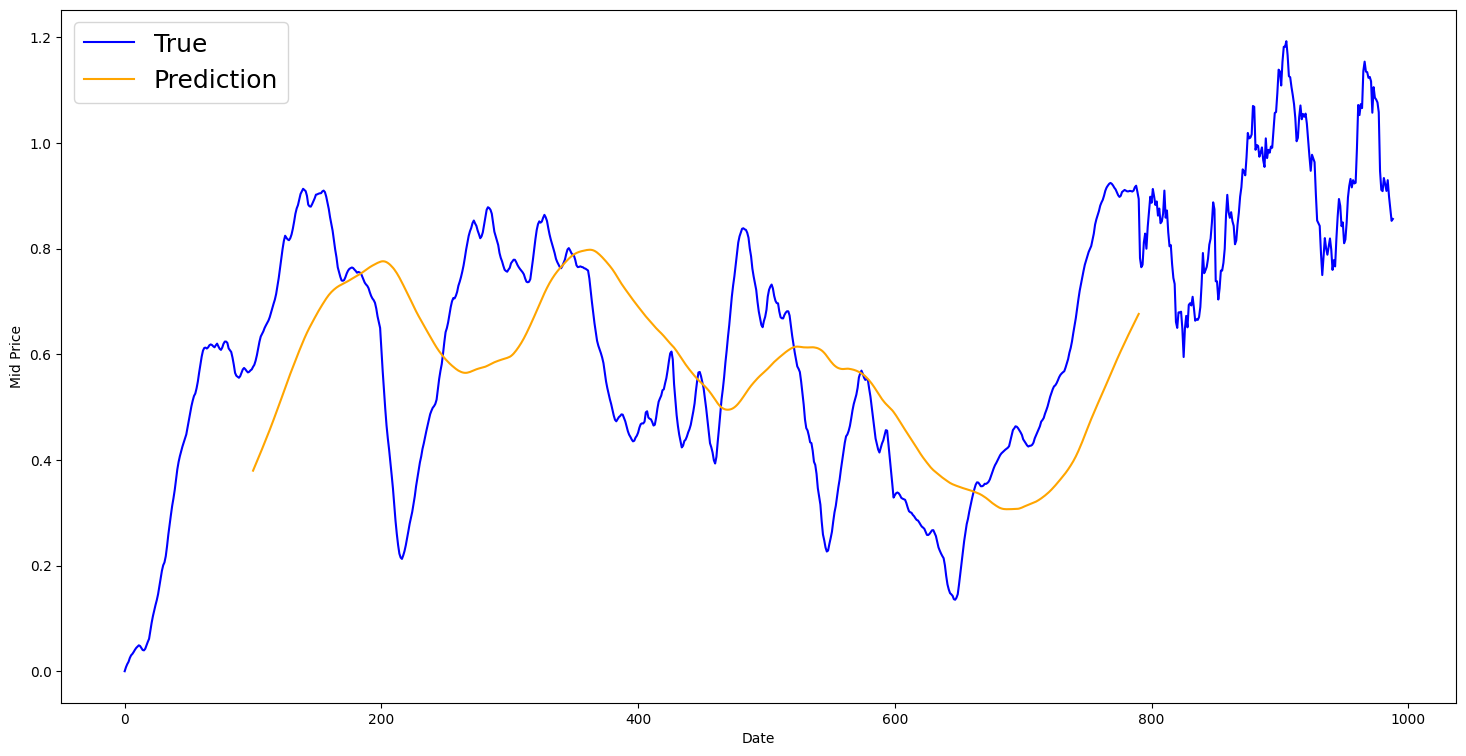

In [114]:
plt.figure(figsize = (18,9))
plt.plot(range(df.shape[0]),all_mid_data,color='b',label='True')
plt.plot(range(window_size,N),std_avg_predictions,color='orange',label='Prediction')
#plt.xticks(range(0,df.shape[0],50),df['Date'].loc[::50],rotation=45)
plt.xlabel('Date')
plt.ylabel('Mid Price')
plt.legend(fontsize=18)
plt.show()

### **Exponential moving average**

In [115]:
window_size = 100
N = train_data.size

run_avg_predictions = []
run_avg_x = []

mse_errors = []

running_mean = 0.0
run_avg_predictions.append(running_mean)

decay = 0.5

for pred_idx in range(1,N):

  running_mean = running_mean*decay + (1.0-decay)*train_data[pred_idx-1]
  run_avg_predictions.append(running_mean)
  mse_errors.append((run_avg_predictions[-1]-train_data[pred_idx])**2)
  run_avg_x.append(date)

print('MSE error for EMA averaging: %5f'%(0.5*np.mean(mse_errors)))

MSE error for EMA averaging: 0.000236


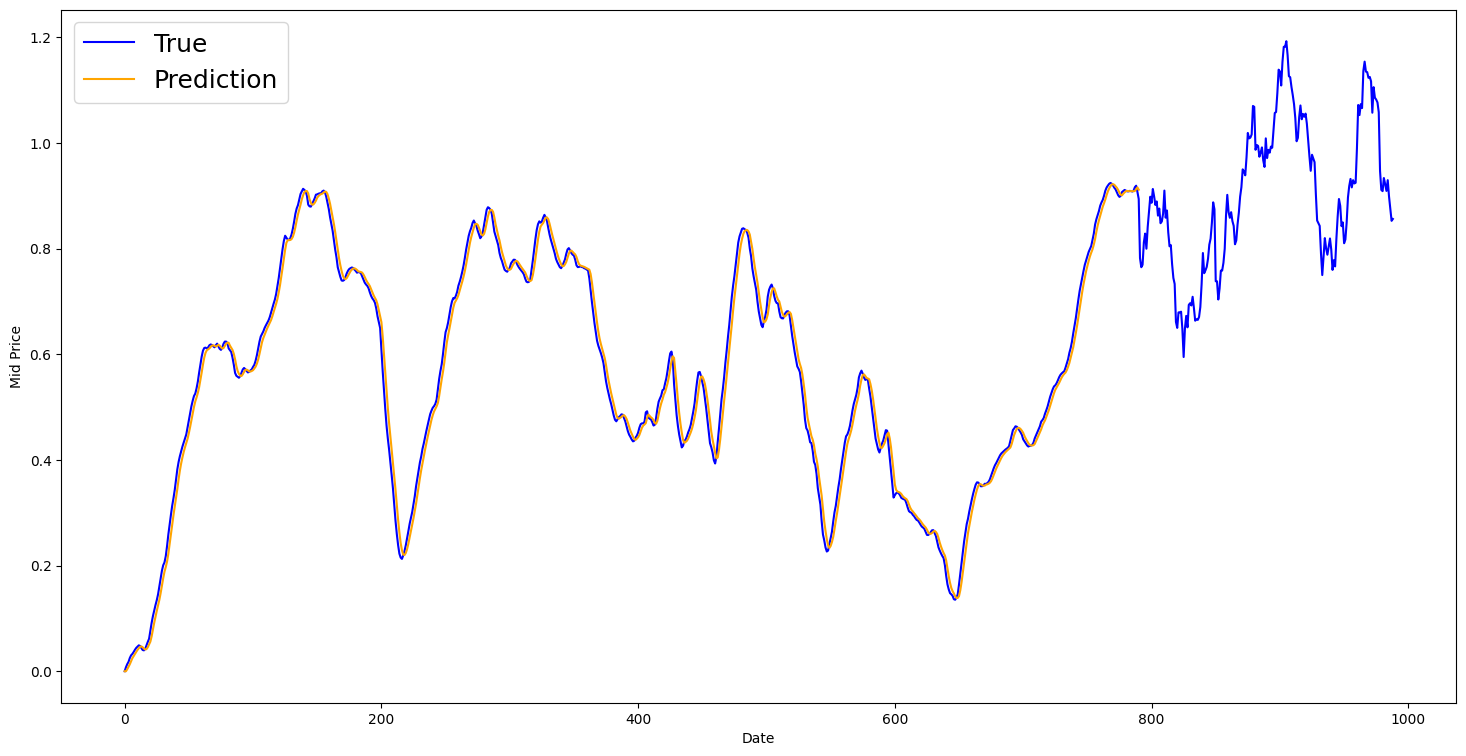

In [116]:
plt.figure(figsize = (18,9))
plt.plot(range(df.shape[0]),all_mid_data,color='b',label='True')
plt.plot(range(0,N),run_avg_predictions,color='orange', label='Prediction')
#plt.xticks(range(0,df.shape[0],50),df['Date'].loc[::50],rotation=45)
plt.xlabel('Date')
plt.ylabel('Mid Price')
plt.legend(fontsize=18)
plt.show()

### **LSTM**

In [117]:
from matplotlib.cbook import print_cycles
class DataGeneratorSeq(object):

    def __init__(self,prices,batch_size,num_unroll):
        self._prices = prices
        self._prices_length = len(self._prices) - num_unroll
        self._batch_size = batch_size
        self._num_unroll = num_unroll
        self._segments = self._prices_length //self._batch_size
        self._cursor = [offset * self._segments for offset in range(self._batch_size)]

    def next_batch(self):
        batch_data = np.zeros((self._batch_size),dtype=np.float32)
        batch_labels = np.zeros((self._batch_size),dtype=np.float32)

        for b in range(self._batch_size):
            if self._cursor[b]+1>=self._prices_length:
                #self._cursor[b] = b * self._segments
                self._cursor[b] = np.random.randint(0,(b+1)*self._segments)

            batch_data[b] = self._prices[self._cursor[b]]
            batch_labels[b]= self._prices[self._cursor[b]+np.random.randint(0,5)]

            self._cursor[b] = (self._cursor[b]+1)%self._prices_length

        return batch_data,batch_labels

    def unroll_batches(self):
        unroll_data,unroll_labels = [],[]
        init_data, init_label = None,None
        for ui in range(self._num_unroll):
            data, labels = self.next_batch()
            unroll_data.append(data)
            unroll_labels.append(labels)

        return unroll_data, unroll_labels

    def reset_indices(self):
        for b in range(self._batch_size):
            self._cursor[b] = np.random.randint(0,min((b+1)*self._segments,self._prices_length-1))


dg = DataGeneratorSeq(train_data,5,5)
u_data, u_labels = dg.unroll_batches()

for ui,(dat,lbl) in enumerate(zip(u_data,u_labels)):
    print('\n\nUnrolled index %d'%ui)
    dat_ind = dat
    lbl_ind = lbl
    print('\tInputs: ',dat )
    print('\n\tOutput:',lbl)



Unrolled index 0
	Inputs:  [0.         0.89834064 0.7360866  0.65528435 0.26321343]

	Output: [0.01342552 0.8869213  0.7360866  0.7087402  0.26692536]


Unrolled index 1
	Inputs:  [0.00759346 0.8869213  0.7370574  0.68156207 0.26679072]

	Output: [0.01342552 0.87487763 0.75966996 0.7474898  0.26156858]


Unrolled index 2
	Inputs:  [0.01342552 0.87487763 0.7420543  0.7087402  0.26692536]

	Output: [0.03274718 0.87487763 0.7420543  0.76871324 0.26692536]


Unrolled index 3
	Inputs:  [0.01780979 0.85916555 0.75966996 0.7298064  0.26156858]

	Output: [0.03274718 0.8335551  0.81803006 0.7474898  0.23439994]


Unrolled index 4
	Inputs:  [0.02506588 0.84633344 0.77796304 0.7474898  0.25583482]

	Output: [0.03274718 0.7978577  0.77796304 0.76871324 0.22277938]


### **Defining hyperameters**

In [118]:
D = 1 # Dimensionality of the data. Since your data is 1-D this would be 1
num_unrollings = 50 # Number of time steps you look into the future.
batch_size = 50 # Number of samples in a batch
num_nodes = [200,200,150] # Number of hidden nodes in each layer of the deep LSTM stack we're using
n_layers = len(num_nodes) # number of layers
dropout = 0.2 # dropout amount

tf.compat.v1.reset_default_graph() # Use compat.v1 to reset the default graph in TensorFlow 2.x

### **Defining inputs and outputs**

In [119]:
# Disable eager execution to enable legacy v1 placeholders and graphs
tf.compat.v1.disable_eager_execution()

# Input data
train_inputs, train_outputs = [], []

for ui in range(num_unrollings):
  train_inputs.append(tf.compat.v1.placeholder(tf.float32, shape=[batch_size,D],name='train_inputs_%d'%ui))
  train_outputs.append(tf.compat.v1.placeholder(tf.float32, shape=[batch_size,1], name = 'train_outputs_%d'%ui))

### **Defining parameters of the LTSM and regression layer**

In [120]:
# Because Keras 3 completely removed BasicLSTMCell and MultiRNNCell, we can implement
# a custom v1-compatible LSTM Cell to execute inside our static TensorFlow graph.

class CustomLSTMCell(object):
    def __init__(self, num_units):
        self.num_units = num_units
        self.state_size = (num_units, num_units) # (c, h)

    def __call__(self, inputs, state, scope=None):
        c, h = state
        input_size = inputs.get_shape().as_list()[1]
        concat_size = input_size + self.num_units

        with tf.compat.v1.variable_scope(scope or "lstm_cell", reuse=tf.compat.v1.AUTO_REUSE):
            W = tf.compat.v1.get_variable("W", shape=[concat_size, 4 * self.num_units],
                                          initializer=tf.compat.v1.glorot_uniform_initializer())
            b = tf.compat.v1.get_variable("b", shape=[4 * self.num_units],
                                          initializer=tf.compat.v1.zeros_initializer())

            concat = tf.concat([inputs, h], axis=1)
            gates = tf.matmul(concat, W) + b

            i, j, f, o = tf.split(value=gates, num_or_size_splits=4, axis=1)

            new_c = c * tf.sigmoid(f + 1.0) + tf.sigmoid(i) * tf.tanh(j)
            new_h = tf.tanh(new_c) * tf.sigmoid(o)

            return new_h, (new_c, new_h)

class CustomDropoutWrapper(object):
    def __init__(self, cell, output_keep_prob):
        self.cell = cell
        self.output_keep_prob = output_keep_prob
        self.state_size = cell.state_size

    def __call__(self, inputs, state, scope=None):
        h, new_state = self.cell(inputs, state, scope)
        h = tf.nn.dropout(h, rate=1.0 - self.output_keep_prob)
        return h, new_state

class CustomMultiRNNCell(object):
    def __init__(self, cells):
        self.cells = cells
        self.state_size = tuple(cell.state_size for cell in cells)

    def __call__(self, inputs, state, scope=None):
        new_states = []
        current_input = inputs
        for i, cell in enumerate(self.cells):
            with tf.compat.v1.variable_scope(f"layer_{i}"):
                current_input, new_state = cell(current_input, state[i])
                new_states.append(new_state)
        return current_input, tuple(new_states)

# Instantiate the custom cells
lstm_cells = [CustomLSTMCell(num_units=num_nodes[li]) for li in range(n_layers)]

drop_lstm_cells = [CustomDropoutWrapper(lstm, output_keep_prob=1.0 - dropout) for lstm in lstm_cells]

drop_multi_cell = CustomMultiRNNCell(drop_lstm_cells)
multi_cell = CustomMultiRNNCell(lstm_cells)

w = tf.compat.v1.get_variable('w', shape=[num_nodes[-1], 1], initializer=tf.compat.v1.glorot_uniform_initializer())
b = tf.compat.v1.get_variable('b', initializer=tf.random.uniform([1], -0.1, 0.1))

### **Calculating LSTM output and feeding it to the regression layer to get the final prediction**

In [121]:
# Create cell state and hidden state variables to maintain the state of the LSTM
initial_state = []
for li in range(n_layers):
  c_var = tf.compat.v1.Variable(tf.compat.v1.zeros([batch_size, num_nodes[li]]), trainable=False)
  h_var = tf.compat.v1.Variable(tf.compat.v1.zeros([batch_size, num_nodes[li]]), trainable=False)
  # We use a standard tuple (c, h) because our custom LSTM cells expect a tuple state
  initial_state.append((c_var, h_var))

# Re-pack as a tuple of layer states
state = tuple(initial_state)

# Collect the outputs of the custom RNN unrolling over the sequence
all_lstm_outputs = []
for x_t in train_inputs:
    # Forward propagate step-by-step through our CustomMultiRNNCell
    output, state = drop_multi_cell(x_t, state)
    all_lstm_outputs.append(output)

# Shape transformation to align with the dense/regression projection layer
# Concat along the time axis, then reshape to 2D [batch * sequence, hidden_dim]
all_lstm_outputs = tf.stack(all_lstm_outputs, axis=0)
all_lstm_outputs = tf.compat.v1.reshape(all_lstm_outputs, [batch_size * num_unrollings, num_nodes[-1]])

# Compute predictions via our output projection weights and biases
all_outputs = tf.compat.v1.nn.xw_plus_b(all_lstm_outputs, w, b)

# Split output predictions back into individual time steps
split_outputs = tf.compat.v1.split(all_outputs, num_unrollings, axis=0)

### **Loss calculation and optimizer**

In [122]:
print('Defining training Loss')
loss = 0.0
# We use the initial_state's individual c_var and h_var tensors from the previous cell
# and assign to them using tf.compat.v1.assign
with tf.control_dependencies([
    tf.compat.v1.assign(initial_state[li][0], state[li][0]) for li in range(n_layers)
] + [
    tf.compat.v1.assign(initial_state[li][1], state[li][1]) for li in range(n_layers)
]):
  for ui in range(num_unrollings):
    loss += tf.reduce_mean(0.5*(split_outputs[ui]-train_outputs[ui])**2)

print('Learning rate decay operations')
global_step = tf.compat.v1.Variable(0, trainable=False)
inc_gstep = tf.compat.v1.assign(global_step, global_step + 1)
tf_learning_rate = tf.compat.v1.placeholder(shape=None, dtype=tf.float32)
tf_min_learning_rate = tf.compat.v1.placeholder(shape=None, dtype=tf.float32)

learning_rate = tf.maximum(
    tf.compat.v1.train.exponential_decay(tf_learning_rate, global_step, decay_steps=1, decay_rate=0.5, staircase=True),
    tf_min_learning_rate)

# Optimizer.
print('TF Optimization operations')
optimizer = tf.compat.v1.train.AdamOptimizer(learning_rate)
gradients, v = zip(*optimizer.compute_gradients(loss))
gradients, _ = tf.clip_by_global_norm(gradients, 5.0)
optimizer = optimizer.apply_gradients(
    zip(gradients, v))

print('\tAll done')

Defining training Loss
Learning rate decay operations
TF Optimization operations
	All done


### **Prediction related calculations**

In [123]:
print('Defining prediction related TF functions')

sample_inputs = tf.compat.v1.placeholder(tf.float32, shape=[1,D])

# Maintaining LSTM state for prediction stage using our custom cell architecture
sample_c, sample_h, initial_sample_state = [], [], []
for li in range(n_layers):
  c_var = tf.compat.v1.Variable(tf.compat.v1.zeros([1, num_nodes[li]]), trainable=False)
  h_var = tf.compat.v1.Variable(tf.compat.v1.zeros([1, num_nodes[li]]), trainable=False)
  sample_c.append(c_var)
  sample_h.append(h_var)
  initial_sample_state.append((c_var, h_var))

# Grouping reset operations using compat.v1 APIs
reset_sample_states = tf.group(*[tf.compat.v1.assign(sample_c[li], tf.compat.v1.zeros([1, num_nodes[li]])) for li in range(n_layers)],
                               *[tf.compat.v1.assign(sample_h[li], tf.compat.v1.zeros([1, num_nodes[li]])) for li in range(n_layers)])

# Unroll predictions sequentially over the inputs
sample_state = tuple(initial_sample_state)
sample_outputs, sample_state = multi_cell(sample_inputs, sample_state)

# Update states sequentially after predictions are made
with tf.control_dependencies([
    tf.compat.v1.assign(sample_c[li], sample_state[li][0]) for li in range(n_layers)
] + [
    tf.compat.v1.assign(sample_h[li], sample_state[li][1]) for li in range(n_layers)
]):
  sample_prediction = tf.compat.v1.nn.xw_plus_b(tf.compat.v1.reshape(sample_outputs, [1, -1]), w, b)

print('\tAll done')

Defining prediction related TF functions
	All done


### **Running the LTSM**

In [124]:
epochs = 30
valid_summary = 1 # Interval you make test predictions

n_predict_once = 10 # Number of steps you continuously predict for

train_seq_length = train_data.size # Full length of the training data

train_mse_ot = [] # Accumulate Train losses
test_mse_ot = [] # Accumulate Test loss
predictions_over_time = [] # Accumulate predictions

# Fix: Use the compat.v1 InteractiveSession
session = tf.compat.v1.InteractiveSession()

# Fix: Use the compat.v1 global variables initializer
tf.compat.v1.global_variables_initializer().run()

# Used for decaying learning rate
loss_nondecrease_count = 0
loss_nondecrease_threshold = 2 # If the test error hasn't increased in this many steps, decrease learning rate

print('Initialized')
average_loss = 0

# Define data generator
data_gen = DataGeneratorSeq(train_data,batch_size,num_unrollings)

x_axis_seq = []

# Start a new forecast every n_predict_once days, from the split to the end
test_points_seq = np.arange(train_seq_length, all_mid_data.size - n_predict_once, n_predict_once).tolist()

for ep in range(epochs):

    # ========================= Training =====================================
    for step in range(train_seq_length//batch_size):

        u_data, u_labels = data_gen.unroll_batches()

        feed_dict = {}
        for ui,(dat,lbl) in enumerate(zip(u_data,u_labels)):
            feed_dict[train_inputs[ui]] = dat.reshape(-1,1)
            feed_dict[train_outputs[ui]] = lbl.reshape(-1,1)

        feed_dict.update({tf_learning_rate: 0.0001, tf_min_learning_rate:0.000001})

        _, l = session.run([optimizer, loss], feed_dict=feed_dict)

        average_loss += l

    # ============================ Validation ==============================
    if (ep+1) % valid_summary == 0:

      average_loss = average_loss/(valid_summary*(train_seq_length//batch_size))

      # The average loss
      if (ep+1)%valid_summary==0:
        print('Average loss at step %d: %f' % (ep+1, average_loss))

      train_mse_ot.append(average_loss)

      average_loss = 0 # reset loss

      predictions_seq = []

      mse_test_loss_seq = []

      # ===================== Updating State and Making Predictions ========================
      for w_i in test_points_seq:
        mse_test_loss = 0.0
        our_predictions = []

        if (ep+1)-valid_summary==0:
          # Only calculate x_axis values in the first validation epoch
          x_axis=[]

        # Feed in the recent past behavior of stock prices
        # to make predictions from that point onwards
        for tr_i in range(w_i-num_unrollings+1,w_i-1):
          current_price = all_mid_data[tr_i]
          feed_dict[sample_inputs] = np.array(current_price).reshape(1,1)
          _ = session.run(sample_prediction,feed_dict=feed_dict)

        feed_dict = {}

        current_price = all_mid_data[w_i-1]

        feed_dict[sample_inputs] = np.array(current_price).reshape(1,1)

        # Make predictions for this many steps
        # Each prediction uses previous prediction as it's current input
        for pred_i in range(n_predict_once):

          pred = session.run(sample_prediction,feed_dict=feed_dict)

          # Fix: Replace deprecated np.asscalar(pred) with pred.item()
          our_predictions.append(pred.item())

          feed_dict[sample_inputs] = np.asarray(pred).reshape(-1,1)

          if (ep+1)-valid_summary==0:
            # Only calculate x_axis values in the first validation epoch
            x_axis.append(w_i+pred_i)

          mse_test_loss += 0.5*(pred-all_mid_data[w_i+pred_i])**2

        session.run(reset_sample_states)

        predictions_seq.append(np.array(our_predictions))

        mse_test_loss /= n_predict_once
        mse_test_loss_seq.append(mse_test_loss)

        if (ep+1)-valid_summary==0:
          x_axis_seq.append(x_axis)

      current_test_mse = np.mean(mse_test_loss_seq)

      # Learning rate decay logic
      if len(test_mse_ot)>0 and current_test_mse > min(test_mse_ot):
          loss_nondecrease_count += 1
      else:
          loss_nondecrease_count = 0

      if loss_nondecrease_count > loss_nondecrease_threshold :
            session.run(inc_gstep)
            loss_nondecrease_count = 0
            print('\tDecreasing learning rate by 0.5')

      test_mse_ot.append(current_test_mse)
      print('\tTest MSE: %.5f'%np.mean(mse_test_loss_seq))
      predictions_over_time.append(predictions_seq)
      print('\tFinished Predictions')

ERROR:tensorflow:An interactive session is already active. This can cause out-of-memory errors or some other unexpected errors (due to the unpredictable timing of garbage collection) in some cases. You must explicitly call `InteractiveSession.close()` to release resources held by the other session(s). Please use `tf.Session()` if you intend to productionize.


Initialized
Average loss at step 1: 3.257943
	Test MSE: 0.01495
	Finished Predictions
Average loss at step 2: 0.551524
	Test MSE: 0.01121
	Finished Predictions
Average loss at step 3: 0.386433
	Test MSE: 0.00985
	Finished Predictions
Average loss at step 4: 0.321414
	Test MSE: 0.00803
	Finished Predictions
Average loss at step 5: 0.265043
	Test MSE: 0.01014
	Finished Predictions
Average loss at step 6: 0.244365
	Test MSE: 0.01229
	Finished Predictions
Average loss at step 7: 0.217625
	Decreasing learning rate by 0.5
	Test MSE: 0.01111
	Finished Predictions
Average loss at step 8: 0.203933
	Test MSE: 0.00844
	Finished Predictions
Average loss at step 9: 0.208008
	Test MSE: 0.00728
	Finished Predictions
Average loss at step 10: 0.192611
	Test MSE: 0.00852
	Finished Predictions
Average loss at step 11: 0.190877
	Test MSE: 0.00689
	Finished Predictions
Average loss at step 12: 0.183645
	Test MSE: 0.00603
	Finished Predictions
Average loss at step 13: 0.188893
	Test MSE: 0.00852
	Finished P

### **Visualising the predictions**

Best epoch: 12


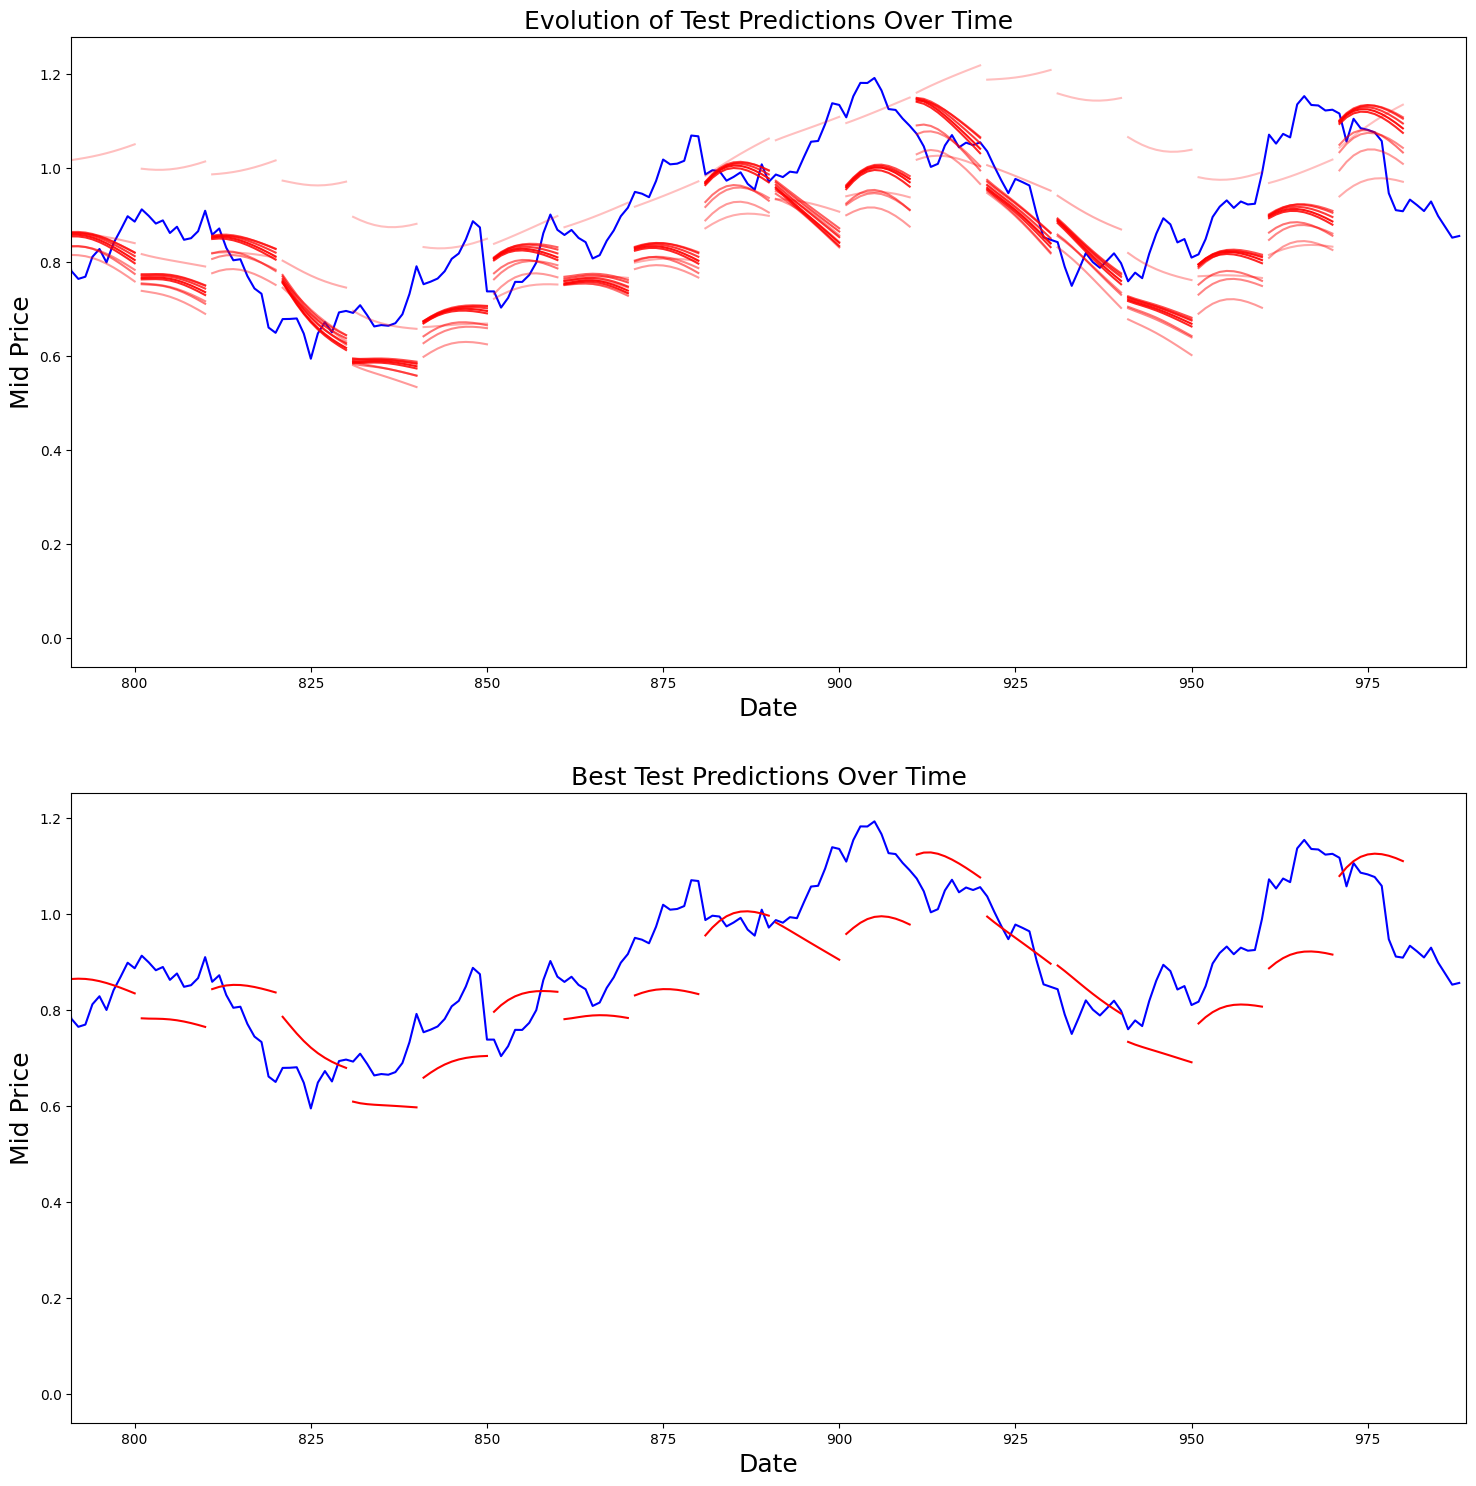

In [125]:
best_prediction_epoch = int(np.argmin(test_mse_ot))
print('Best epoch:', best_prediction_epoch + 1)

plt.figure(figsize=(18,18))

# ---------- Evolution of predictions over training ----------
plt.subplot(2,1,1)
plt.plot(range(df.shape[0]), all_mid_data, color='b')

start_alpha = 0.25
alpha = np.arange(start_alpha, 1.1, (1.0 - start_alpha) / len(predictions_over_time[::3]))
for p_i, p in enumerate(predictions_over_time[::3]):
    for xval, yval in zip(x_axis_seq, p):
        plt.plot(xval, yval, color='r', alpha=alpha[p_i])

plt.title('Evolution of Test Predictions Over Time', fontsize=18)
plt.xlabel('Date', fontsize=18)
plt.ylabel('Mid Price', fontsize=18)
plt.xlim(split, len(all_mid_data))

# ---------- Best epoch ----------
plt.subplot(2,1,2)
plt.plot(range(df.shape[0]), all_mid_data, color='b')
for xval, yval in zip(x_axis_seq, predictions_over_time[best_prediction_epoch]):
    plt.plot(xval, yval, color='r')

plt.title('Best Test Predictions Over Time', fontsize=18)
plt.xlabel('Date', fontsize=18)
plt.ylabel('Mid Price', fontsize=18)
plt.xlim(split, len(all_mid_data))

plt.show()